# MapleFreight Logistics: Delivery Delay Prediction & Slack Alerts

End-to-end workflow: raw shipment export → cleaning → EDA → features → baseline and
improved classifiers → threshold choice → explainability → a real Slack alert to
`#dispatch-alerts` → recommendations.

**Contents**
1. Context · 2. Problem statement · 3. Objectives
4. Setup
5. Data understanding
6. Data preprocessing (cleaning)
7. Exploratory data analysis
8. Feature engineering
9. Data preparation
10. Data modelling (baseline → candidates → tuning)
11. Alert threshold selection
12. Model evaluation on the held-out test set
13. Model explainability
14. Slack alert integration
15. Recommendations
16. Limitations and next steps

## 1. Context

MapleFreight Logistics moves about **8,000 shipments a week** across Ontario, Quebec and the
Prairies. Contracts carry on-time guarantees, so every late delivery costs service credits and
re-delivery charges. On-time performance has dropped from **94% to 88%** during the year, and the
company currently learns of a late shipment only when the customer calls.

## 2. Problem statement

Delays are discovered only after the delivery window has closed. The result is paid-out service
credits, expedited re-deliveries, and complaints reaching the account manager before dispatch
knows anything is wrong. The aim is to **predict, at dispatch time, which in-transit shipments will
arrive late** and to alert dispatch in Slack while time remains to re-route or warn the customer.

## 3. Objectives

1. Analyse shipment, route and carrier data to identify the main drivers of late delivery.
2. Build a classifier that predicts `delivered_late` (1 = missed the promised window).
3. Send automatic Slack alerts to `#dispatch-alerts` for high-risk shipments.
4. Turn the findings into actionable recommendations for on-time performance.

**Success criteria.** About 21% of shipments are late, so predicting "on time" for every shipment
scores ~79% accuracy while catching zero late shipments. Accuracy is therefore not the metric.
Models are judged on **PR-AUC** (ranking quality on the minority class), and the deployed alert on
**recall** (share of late shipments caught) and **precision** (share of alerts that are real).

## 4. Setup

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import shap
import sklearn
import xgboost
from dotenv import find_dotenv, load_dotenv
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
DATA_PATH = Path("data/maplefreight_delivery_delay_dataset.csv")
TARGET = "delivered_late"
WEEKLY_SHIPMENTS = 8_000

# Chart palette: one blue for single-series charts, blue/red as the diverging pair.
BLUE, ORANGE, RED, GREY, INK_2 = "#2a78d6", "#eb6834", "#e34948", "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ae", "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"xgboost {xgboost.__version__} | shap {shap.__version__}")

pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1 | shap 0.52.0


## 5. Data understanding

Load the raw export as-is and profile the data before changing anything.

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns")
raw.head()

6,035 rows × 23 columns


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.000,257.100,2,0,7.530,55.000,5.100,6.100,Fog,37.200,0.291,1,146.390,7.550,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.800,734.100,0,0,1.000,69.000,5.300,4.200,Snow,77.400,0.236,0,155.070,1.170,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.000,680.800,0,0,7.120,-13.000,1.400,2.800,Rain,36.500,0.344,0,163.440,6.470,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.100,"1,292.200",0,0,7.610,-20.000,4.000,14.800,Fog,51.200,0.491,2,NaN,8.030,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.500,"3,327.100",1,0,12.900,28.000,2.900,1.600,Clear,82.700,0.423,1,263.220,13.490,0


In [3]:
CAT_COLS = ["origin_city", "destination_city", "carrier", "service_level", "goods_type",
            "customer_priority_tier", "weather_condition"]

profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique": raw.nunique(),
})
profile

,dtype,missing,missing_%,unique
shipment_id,str,0,0.000,6000
origin_city,str,0,0.000,7
destination_city,str,0,0.000,10
carrier,str,0,0.000,5
service_level,str,0,0.000,6
goods_type,str,0,0.000,5
customer_priority_tier,str,0,0.000,3
shipment_month,int64,0,0.000,12
distance_km,float64,0,0.000,4550
weight_kg,float64,0,0.000,5143


In [4]:
for col in CAT_COLS:
    print(f"{col}:\n  {raw[col].value_counts(dropna=False).to_dict()}\n")

origin_city:
  {'Toronto ON': 1593, 'Mississauga ON': 1019, 'Montreal QC': 1017, 'Calgary AB': 762, 'Ottawa ON': 730, 'London ON': 460, 'Winnipeg MB': 454}

destination_city:
  {'Sudbury ON': 641, 'Toronto ON': 638, 'Regina SK': 634, 'Winnipeg MB': 614, 'Hamilton ON': 604, 'Quebec City QC': 598, 'Edmonton AB': 592, 'Montreal QC': 587, 'Calgary AB': 578, 'Ottawa ON': 549}

carrier:
  {'MapleFreight Fleet': 2391, 'NorthStar Carriers': 1164, 'PrairieLine': 932, 'QuebecExpress': 924, 'Contract Owner-Op': 624}

service_level:
  {'Standard': 3219, 'Express': 1442, 'Economy': 1254, 'standard': 74, 'express': 27, 'economy': 19}

goods_type:
  {'General Freight': 2974, 'Refrigerated': 924, 'Fragile': 895, 'Bulk': 744, 'Hazardous': 498}

customer_priority_tier:
  {'Silver': 2775, 'Bronze': 2092, 'Gold': 1168}

weather_condition:
  {'Clear': 2976, 'Rain': 1332, 'Snow': 869, 'Fog': 423, 'Storm': 285, nan: 150}



In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
shipment_month,"6,035.000",6.544,3.448,1.000,4.000,7.000,10.000,12.000
distance_km,"6,035.000",632.193,319.246,80.500,398.600,571.100,804.850,"2,556.700"
weight_kg,"6,035.000","6,928.251","83,755.150",30.000,496.000,827.100,"1,286.300","2,999,300.000"
num_stops,"6,035.000",2.477,1.707,0.000,1.000,2.000,4.000,5.000
is_cross_border,"6,035.000",0.113,0.317,0.000,0.000,0.000,0.000,1.000
scheduled_transit_hours,"6,035.000",10.500,4.759,1.000,7.060,9.850,13.175,37.400
pickup_delay_minutes,"6,035.000",20.368,30.619,-20.000,-6.000,18.000,41.000,146.000
driver_experience_years,"5,825.000",6.498,4.659,0.200,3.200,5.400,8.600,35.000
vehicle_age_years,"6,035.000",5.489,3.434,0.100,3.000,4.800,7.200,20.000
traffic_index,"5,914.000",55.146,17.593,5.000,43.300,55.000,67.200,100.000


### 5.1 Data-quality checks

The profile above hints at three problems: inconsistent `service_level` spellings, an extreme
`weight_kg` maximum, and duplicated IDs. Each is confirmed below.

In [6]:
print("Exact duplicate rows      :", raw.duplicated().sum())
print("Duplicated shipment_id    :", raw["shipment_id"].duplicated().sum())

dup_ids = raw.loc[raw["shipment_id"].duplicated(keep=False)]
conflicting = dup_ids.loc[~dup_ids.duplicated(keep=False)].sort_values("shipment_id")
print("\nIDs that repeat with different values (only service_level differs):")
display(conflicting[["shipment_id", "service_level", "carrier", "distance_km", TARGET]])

Exact duplicate rows      : 32
Duplicated shipment_id    : 35

IDs that repeat with different values (only service_level differs):


,shipment_id,service_level,carrier,distance_km,delivered_late
861,SHP-101906,Express,NorthStar Carriers,333.700,0
3030,SHP-101906,standard,NorthStar Carriers,333.700,0
1228,SHP-102476,Standard,QuebecExpress,949.000,1
4033,SHP-102476,standard,QuebecExpress,949.000,1
441,SHP-103022,Standard,Contract Owner-Op,404.400,0
4375,SHP-103022,standard,Contract Owner-Op,404.400,0


In [7]:
w = raw["weight_kg"]
print("weight_kg percentiles:", w.quantile([0.5, 0.99, 0.995, 1.0]).round(1).to_dict())
print("Rows with weight_kg > 50,000:", (w > 50_000).sum())
print("Largest plausible weight (<= 50,000):", w[w <= 50_000].max())
print("Smallest suspicious weight (> 50,000):", w[w > 50_000].min())

weight_kg percentiles: {0.5: 827.1, 0.99: 3360.6, 0.995: 535051.0, 1.0: 2999300.0}
Rows with weight_kg > 50,000: 40
Largest plausible weight (<= 50,000): 5044.0
Smallest suspicious weight (> 50,000): 170900.0


### 5.2 How is the target defined? (leakage check)

`actual_transit_hours` is recorded on delivery. If the target is derived from the column, using
the column as a feature would make the model look perfect offline and useless in production.

In [8]:
ratio = raw["actual_transit_hours"] / raw["scheduled_transit_hours"]
summary = ratio.groupby(raw[TARGET]).agg(["count", "min", "median", "max"])
summary.index = ["on time (0)", "late (1)"]
display(summary)
print(f"Largest on-time ratio: {ratio[raw[TARGET] == 0].max():.3f} | "
      f"smallest late ratio: {ratio[raw[TARGET] == 1].min():.3f}")

,count,min,median,max
on time (0),4793,0.880,0.969,1.060
late (1),1242,1.121,1.357,1.600


Largest on-time ratio: 1.060 | smallest late ratio: 1.121


In [9]:
target_counts = raw[TARGET].value_counts()
late_share = raw[TARGET].mean()
print(f"On time: {target_counts[0]:,} | Late: {target_counts[1]:,} | Late share: {late_share:.1%}")
print(f"Accuracy of always predicting 'on time': {1 - late_share:.1%}  (catches 0 late shipments)")

On time: 4,793 | Late: 1,242 | Late share: 20.6%
Accuracy of always predicting 'on time': 79.4%  (catches 0 late shipments)


**Key findings: data understanding**

- The file has 6,035 rows and 23 columns.
- Several columns have missing values: fuel cost (240 rows), driver experience (210), weather (150)
  and traffic index (121). Each is under 4% of the data.
- `service_level` is sometimes written in lower case (120 rows), for example `standard` instead
  of `Standard`.
- Duplicates: 32 rows are exact copies, and 3 more shipment IDs appear twice with a different
  `service_level`.
- 40 weights are far too large (170,900 to 2,999,300) when every other weight is 5,044 kg or
  less. The oversized values were recorded in **grams**, not kilograms.
- A shipment counts as late when delivery takes more than about 10% longer than promised. No
  on-time shipment went over 1.06 times the scheduled hours, and every late shipment went over
  1.12 times. As a result, `actual_transit_hours` gives away the answer, and the value is only
  known after delivery. **The column is left out of the model.**
- 20.6% of shipments are late. A model that always says "on time" would be 79% accurate but would
  catch no late shipments, so accuracy is a poor score here.

## 6. Data preprocessing (cleaning)

Cleaning is row-level and deterministic, so the step can safely run before the train/test split.
Anything learned from the data (imputation medians, scaling) happens **inside the model
pipeline** and is fitted on training folds only.

In [10]:
WEIGHT_GRAMS_CUTOFF = 50_000  # no real shipment here exceeds ~5,000 kg, so values above are grams


def clean_shipments(df: pd.DataFrame) -> pd.DataFrame:
    """Fix spellings, unit errors and duplicates in the raw shipment export."""
    df = df.copy()
    steps = [("raw export", len(df))]

    for col in ["shipment_id"] + CAT_COLS:
        df[col] = df[col].str.strip()
    df["service_level"] = df["service_level"].str.title()      # 'standard' -> 'Standard'

    in_grams = df["weight_kg"] > WEIGHT_GRAMS_CUTOFF
    df.loc[in_grams, "weight_kg"] = df.loc[in_grams, "weight_kg"] / 1000
    print(f"Converted {in_grams.sum()} weight values from grams to kg")

    df = df.drop_duplicates()
    steps.append(("drop exact duplicates", len(df)))
    df = df.drop_duplicates(subset="shipment_id", keep="first")
    steps.append(("one row per shipment_id", len(df)))

    # A missing forecast is a state dispatch can actually be in, so keep the missing value as its own level.
    df["weather_condition"] = df["weather_condition"].fillna("Unknown")

    display(pd.DataFrame(steps, columns=["step", "rows"]))
    return df.reset_index(drop=True)


df = clean_shipments(raw)

Converted 40 weight values from grams to kg


,step,rows
0,raw export,6035
1,drop exact duplicates,6001
2,one row per shipment_id,6000


In [11]:
range_checks = {
    "shipment_id unique":            df["shipment_id"].is_unique,
    "shipment_month in 1..12":       df["shipment_month"].between(1, 12).all(),
    "traffic_index in 0..100":       df["traffic_index"].dropna().between(0, 100).all(),
    "route_congestion_score in 0..1": df["route_congestion_score"].between(0, 1).all(),
    "weight_kg <= 10,000":           (df["weight_kg"] <= 10_000).all(),
    "distance & hours > 0":          (df[["distance_km", "scheduled_transit_hours"]] > 0).all().all(),
    "service_level has 3 levels":    df["service_level"].nunique() == 3,
}
display(pd.Series(range_checks, name="passes").to_frame())
assert all(range_checks.values())

remaining_missing = df.isna().sum()
remaining_missing = remaining_missing[remaining_missing > 0]
missing_vs_late = pd.DataFrame({
    "missing": remaining_missing,
    "late rate if missing": [df.loc[df[c].isna(), TARGET].mean() for c in remaining_missing.index],
    "late rate if present": [df.loc[df[c].notna(), TARGET].mean() for c in remaining_missing.index],
})
missing_vs_late

,passes
shipment_id unique,True
shipment_month in 1..12,True
traffic_index in 0..100,True
route_congestion_score in 0..1,True
"weight_kg <= 10,000",True
distance & hours > 0,True
service_level has 3 levels,True


,missing,late rate if missing,late rate if present
driver_experience_years,210,0.224,0.205
traffic_index,120,0.183,0.206
fuel_cost_cad,240,0.192,0.206


**Key findings: cleaning**

- 6,035 rows became **6,000 shipments** after duplicates were removed. One pair (SHP-101906)
  disagreed on `service_level` (`Express` against `standard`), so the first record was kept.
- The 40 weights recorded in grams were converted to kg. All sanity checks pass.
- Shipments with a missing value are late about as often as the rest, so the gaps look random
  and filling with the median is reasonable.

## 7. Exploratory data analysis

The question is which factors known **at dispatch** move the late rate. The dashed line on each
chart marks the overall late rate (20.6%). A guide follows each chart to explain how to read the
chart and what stands out.

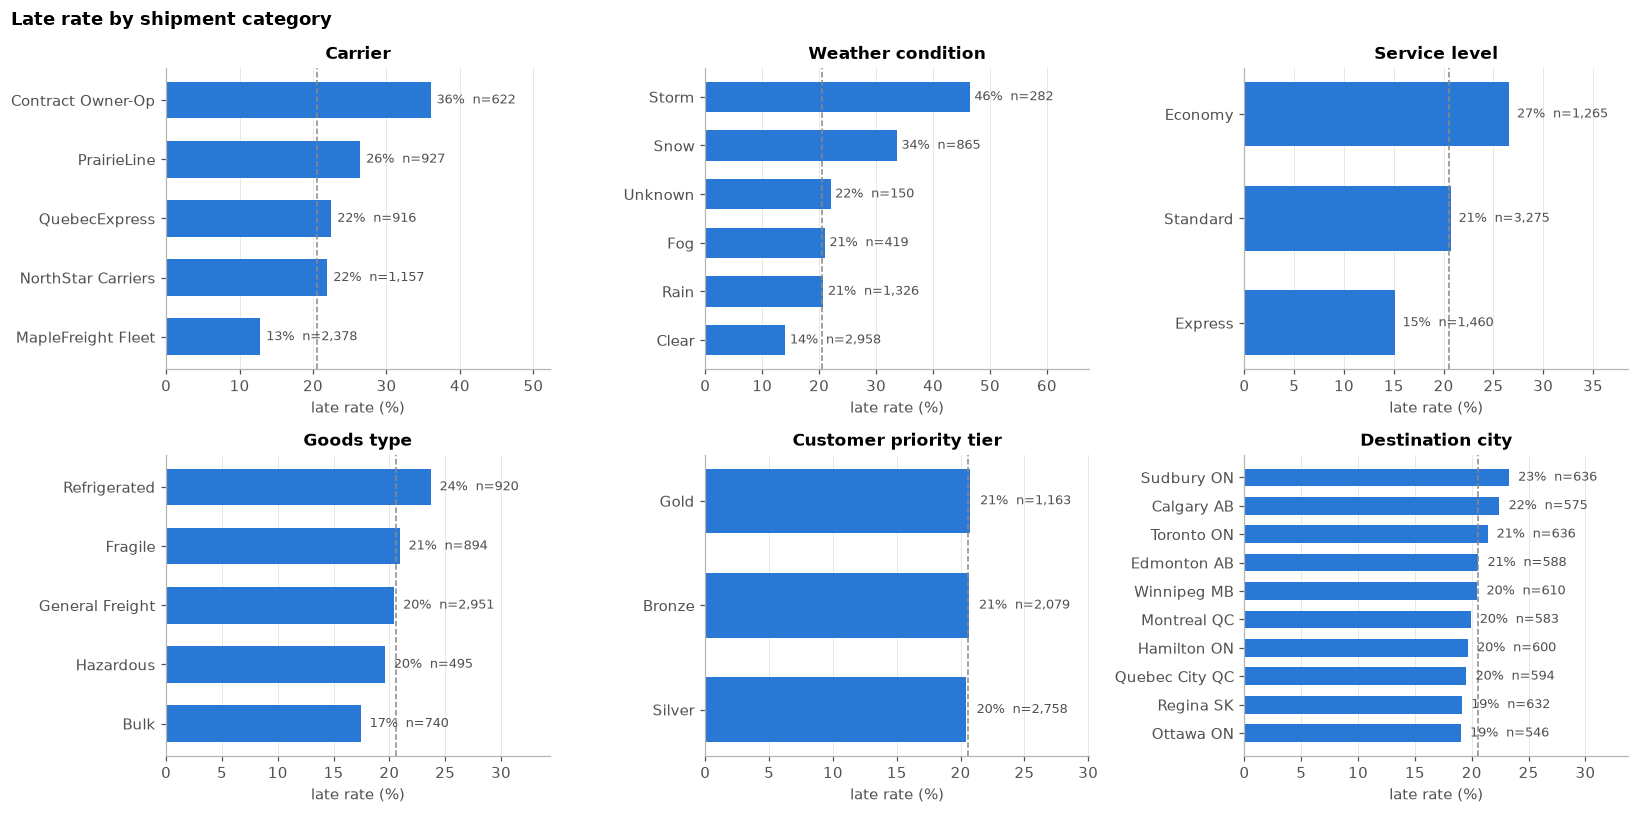

In [12]:
OVERALL = df[TARGET].mean()


def late_rate_barh(ax, col, min_n=30):
    r = df.groupby(col)[TARGET].agg(["mean", "size"]).query("size >= @min_n").sort_values("mean")
    ax.barh(r.index.astype(str), r["mean"] * 100, color=BLUE, height=0.62)
    ax.axvline(OVERALL * 100, color=GREY, ls="--", lw=1)
    for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
        ax.text(m * 100 + 0.8, i, f"{m:.0%}  n={n:,}", va="center", fontsize=8.5, color=INK_2)
    ax.set_xlim(0, r["mean"].max() * 100 * 1.45)
    ax.set_xlabel("late rate (%)")
    ax.set_title(col.replace("_", " ").capitalize())
    ax.grid(axis="y", visible=False)


fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, col in zip(axes.flat, ["carrier", "weather_condition", "service_level", "goods_type",
                               "customer_priority_tier", "destination_city"]):
    late_rate_barh(ax, col)
fig.suptitle("Late rate by shipment category", fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Chart guide: late rate by shipment category**

*What the chart shows.* Six panels give the percentage of shipments delivered late within each
group of a category column: carrier, weather condition, service level, goods type, customer
priority tier and destination city. The label beside each bar adds the group size (n). The
dashed vertical line marks the overall late rate of 20.6%. A bar ending to the right of the line
is worse than average, and a bar ending to the left is better.

*What stands out.*
- **Carrier:** Contract Owner-Op is the longest bar at 36% (n=622), followed by PrairieLine at
  26%, QuebecExpress at 22% and NorthStar Carriers at 22%. MapleFreight Fleet is the only clearly
  better-than-average carrier at 13%, and also handles the most shipments (n=2,378).
- **Weather:** Storm (46%, n=282) and Snow (34%, n=865) lie far to the right of the dashed line.
  Clear weather is the safest at 14%. Fog and Rain (both 21%) sit close to average, and the 150
  shipments with an unknown forecast (22%) also look average.
- **Service level:** Economy is late 27% of the time, Standard 21% and Express 15%.
- **Goods type:** Refrigerated is highest at 24% and Bulk lowest at 17%. The spread is modest.
- **Customer tier:** Gold, Silver and Bronze all land within one point of 21%, so a higher
  priority tier brings no better on-time performance.
- **Destination city:** all ten cities fall between 19% and 23%, so destination alone says
  little about lateness.

*Takeaway.* Carrier, weather and service level separate shipments clearly. Customer tier and city
do not.

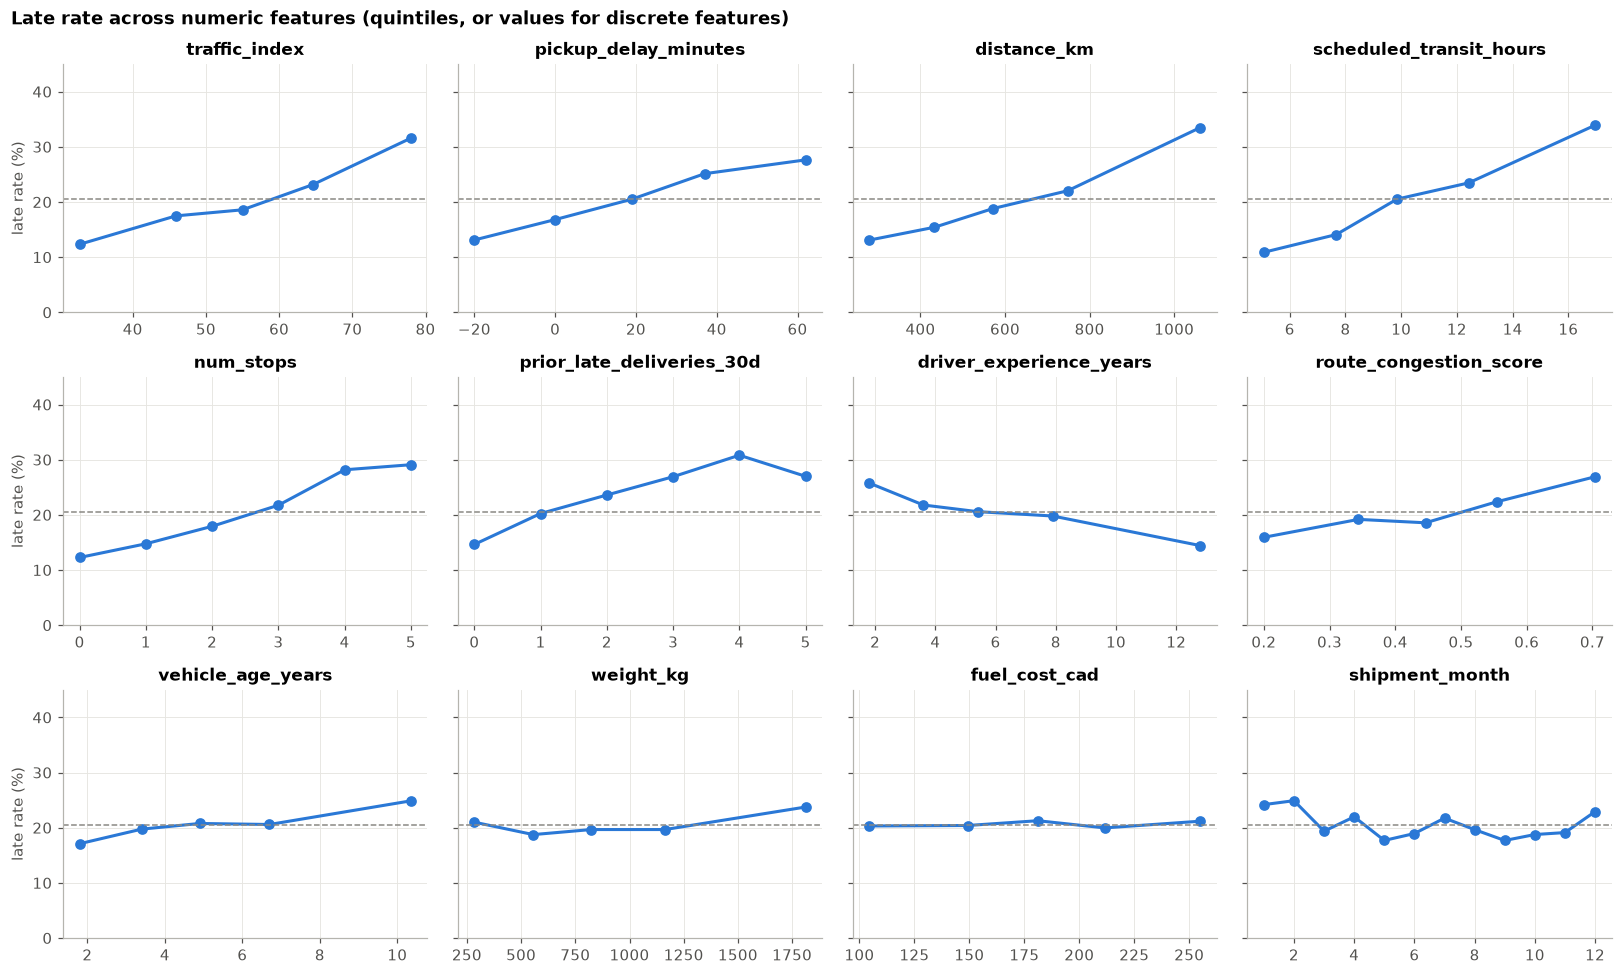

In [13]:
NUMERIC_EDA = ["traffic_index", "pickup_delay_minutes", "distance_km", "scheduled_transit_hours",
               "num_stops", "prior_late_deliveries_30d", "driver_experience_years",
               "route_congestion_score", "vehicle_age_years", "weight_kg", "fuel_cost_cad",
               "shipment_month"]


def binned_late_rate(col, q=5, min_n=40):
    s = df[col]
    if s.nunique() <= 12:                      # discrete: use the values themselves
        groups = s
    else:                                      # continuous: quintiles, plotted at the bin median
        groups = pd.qcut(s, q, duplicates="drop")
    g = df.groupby(groups, observed=True).agg(x=(col, "median"), rate=(TARGET, "mean"),
                                              n=(TARGET, "size"))
    return g[g["n"] >= min_n]


fig, axes = plt.subplots(3, 4, figsize=(15, 9), sharey=True)
for ax, col in zip(axes.flat, NUMERIC_EDA):
    g = binned_late_rate(col)
    ax.plot(g["x"], g["rate"] * 100, color=BLUE, lw=2, marker="o", ms=6)
    ax.axhline(OVERALL * 100, color=GREY, ls="--", lw=1)
    ax.set_title(col)
    ax.set_ylim(0, 45)
for ax in axes[:, 0]:
    ax.set_ylabel("late rate (%)")
fig.suptitle("Late rate across numeric features (quintiles, or values for discrete features)",
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Chart guide: late rate across numeric features**

*What the chart shows.* Twelve small line charts, one per numeric column, share the same
vertical axis (late rate from 0% to 45%). For columns with many distinct values, shipments are
split into five equal-sized groups (quintiles), and each dot sits at the median value of one
group. For columns with few values (stops, prior late deliveries, month), each dot is one actual
value. The dashed horizontal line marks the overall late rate of 20.6%. A line that climbs from
left to right means higher values bring more lateness, and a flat line means no relationship.

*Steep and steady climbs (strong drivers).*
- `traffic_index`: from about 12% in the quietest fifth to about 32% in the busiest fifth.
- `scheduled_transit_hours` and `distance_km`: from 11% to 34% for both. The two
  panels look alike because longer trips are promised more hours.
- `num_stops`: from 12% with no stops to 29% with five stops.
- `pickup_delay_minutes`: from about 13% for early pickups to about 28% for the latest pickups.
- `prior_late_deliveries_30d`: from 15% with no recent late deliveries to 31% with four. The dip
  at five reflects very few shipments, so the drop should not be over-read.

*Moderate effects.* `route_congestion_score` rises from 16% to 27%. `driver_experience_years`
falls from 26% (about two years of experience) to 14% (about thirteen years), the only
protective trend. `vehicle_age_years` rises from 17% to 25%, mostly in the oldest fifth.

*Little or no effect.* `weight_kg` stays near 19% to 21% apart from a small rise to 24% for the
heaviest fifth. `fuel_cost_cad` is flat. `shipment_month` wanders between 18% and 25%, highest in
January and February, with no clear seasonal pattern.

*Takeaway.* Lateness grows with route length, stops, traffic and a late start, and shrinks with
driver experience. Weight and fuel cost can be ignored.

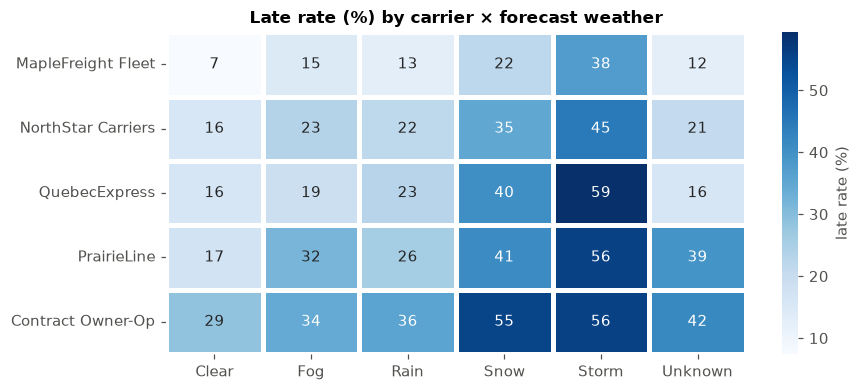

In [14]:
pivot = df.pivot_table(index="carrier", columns="weather_condition", values=TARGET, aggfunc="mean")
pivot = pivot.loc[pivot.mean(axis=1).sort_values().index,
                  ["Clear", "Fog", "Rain", "Snow", "Storm", "Unknown"]]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
sns.heatmap(pivot * 100, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "late rate (%)"},
            linewidths=2, linecolor="white", ax=ax)
ax.set_title("Late rate (%) by carrier × forecast weather")
ax.set_xlabel("")
ax.set_ylabel("")
plt.show()

**Chart guide: late rate by carrier and forecast weather**

*What the chart shows.* Each row is a carrier and each column a weather forecast. The number in
each cell is the late rate (%) for that combination, and darker blue means more lateness.
Carriers are sorted with the best on-time record at the top.

*What stands out.*
- **Carrier gaps persist in every weather type.** MapleFreight Fleet is the lightest row, from 7%
  in clear weather to 38% in a storm. Contract Owner-Op is the darkest row, at 29% even in clear
  weather and 55% to 56% in snow and storms.
- **Storm is the darkest column for every carrier**, ranging from 38% (Fleet) to 59%
  (QuebecExpress, the highest cell on the chart). Snow is the next worst, from 22% (Fleet) to 55%
  (Owner-Op).
- **The two risks add up.** Fleet in rain (13%) is far safer than Owner-Op in clear weather (29%),
  yet Fleet in a storm (38%) is still worse than every carrier in clear weather.
- Fog and Rain add a moderate amount of risk (a few points to about 15 points over clear
  weather), while Snow and Storm add far more.
- The "Unknown" column covers only 150 shipments in total, from 12 (Owner-Op) to 56 (Fleet) per
  carrier. Single cells such as 39% (PrairieLine, 28 shipments) and 42% (Owner-Op, 12 shipments)
  rest on tiny counts and should not be over-read.

*Takeaway.* Weather and carrier act together, so the worst case is an owner-operator on a snow
or storm day, with more than half of shipments late.

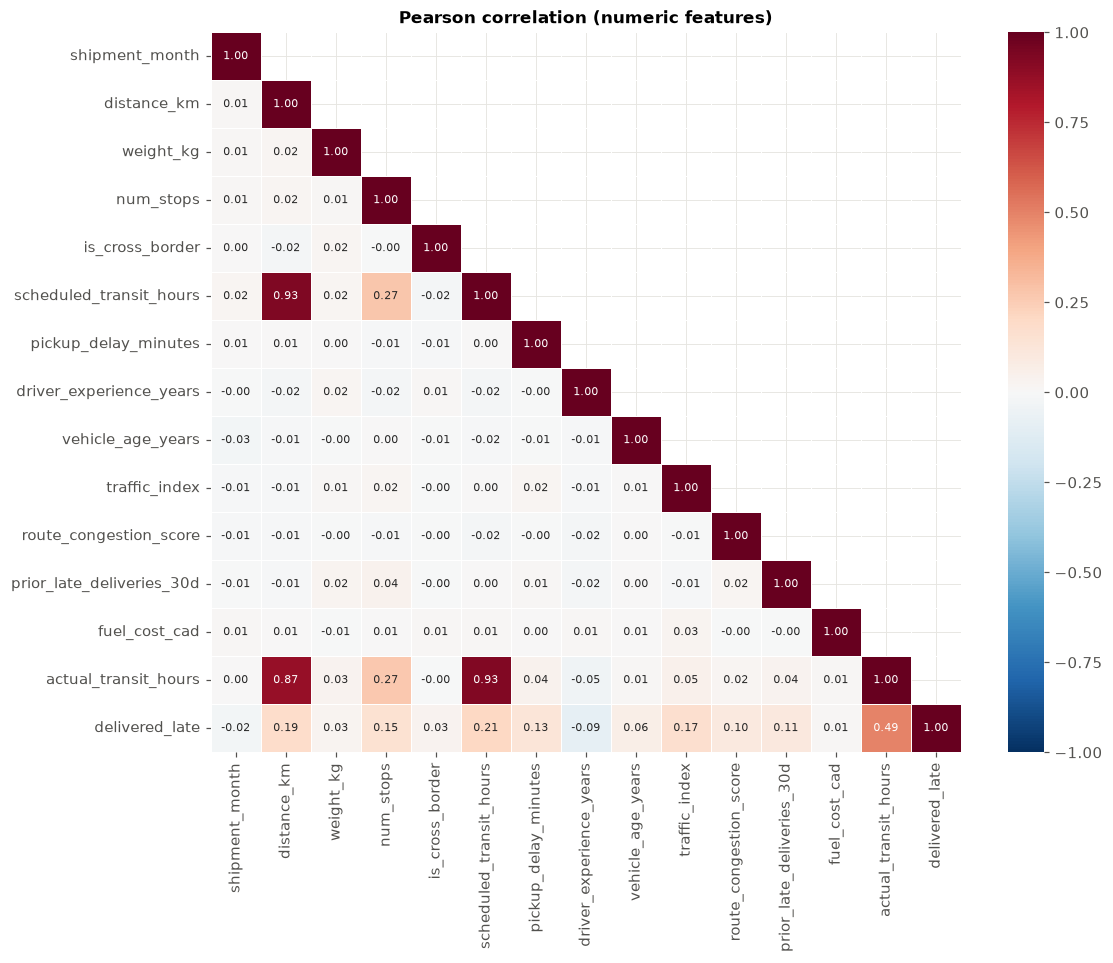

In [15]:
num_cols_all = [c for c in df.select_dtypes("number").columns if c != TARGET]
corr = df[num_cols_all + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, ax=ax)
ax.set_title("Pearson correlation (numeric features)")
plt.show()

**Chart guide: correlation between numeric columns**

*What the chart shows.* Each square gives the Pearson correlation between two numeric columns,
from -1 (one rises as the other falls) through 0 (no straight-line relationship) to +1 (both rise
together). Red is positive, blue is negative, and white is near zero. Only the lower triangle is
drawn because the upper triangle would repeat the same numbers. The bottom row shows how strongly
each column moves with `delivered_late`.

*Relationship with lateness (bottom row).*
- `actual_transit_hours` is the strongest at 0.49, but the value is only known after delivery and
  defines the target, so the column is excluded from modelling (leakage).
- Among usable columns, `scheduled_transit_hours` (0.21), `distance_km` (0.19), `traffic_index`
  (0.17), `num_stops` (0.15), `pickup_delay_minutes` (0.13), `prior_late_deliveries_30d` (0.11)
  and `route_congestion_score` (0.10) all correlate positively.
- `driver_experience_years` is the only meaningful negative value (-0.09), meaning more
  experience goes with fewer late deliveries.
- `weight_kg` (0.03), `is_cross_border` (0.03), `shipment_month` (-0.02) and `fuel_cost_cad`
  (0.01) are essentially zero.

*Relationships between predictors.*
- Nearly every pair is close to 0, so most columns carry independent information.
- The exceptions are `distance_km` with `scheduled_transit_hours` (0.93, because longer trips are
  promised more hours) and `scheduled_transit_hours` with `num_stops` (0.27).

*Takeaway.* No usable column correlates with lateness above 0.21, so lateness comes from several
factors acting together and not from one dominant cause. Correlation measures straight-line links
only, so the model results in later sections give the fuller picture.

In [16]:
def late_rate_spread(col, min_n=40):
    """Gap between the highest and lowest late rate across a feature's levels or quintiles."""
    if col in CAT_COLS:
        g = df.groupby(col)[TARGET].agg(["mean", "size"])
        g = g[g["size"] >= min_n]
        return g["mean"].max() - g["mean"].min()
    g = binned_late_rate(col, min_n=min_n)
    return g["rate"].max() - g["rate"].min()


drivers = (pd.Series({c: late_rate_spread(c) for c in CAT_COLS + NUMERIC_EDA + ["is_cross_border"]})
           .sort_values(ascending=False).mul(100).round(1).rename("late-rate spread (pp)"))
drivers.to_frame()

,late-rate spread (pp)
weather_condition,32.400
carrier,23.200
scheduled_transit_hours,23.000
distance_km,20.400
traffic_index,19.200
num_stops,16.800
prior_late_deliveries_30d,16.200
pickup_delay_minutes,14.500
service_level,11.500
driver_experience_years,11.400


**Key findings: what makes shipments late (one factor at a time)**

- **Weather and carrier matter most.** Storms are late 46% of the time and snow 34%, compared with
  14% in clear weather. Contract owner-operators are late 36% of the time, almost three times as
  often as the in-house MapleFreight Fleet (13%).
- **The two effects add up.** An owner-operator in snow or a storm is late more than half the
  time. The in-house fleet in clear weather is late only 7% of the time.
- **Busy or long routes are riskier.** The late rate goes up with traffic, trip length, distance,
  number of stops, pickup delay, route congestion, and the carrier's recent late deliveries.
- **Drivers and vehicles:** drivers with the least experience are late 26% of the time, against
  14% for the most experienced. Older vehicles are late a bit more often.
- **Service level:** Economy shipments are late 27% of the time and Express 15%.
- **Small effects:** refrigerated goods (24%) and January to February pickups (about 24% to 25%)
  are slightly worse than average.
- **No real effect:** customer tier (about 21% for Gold, Silver and Bronze alike), origin and
  destination city, weight and fuel cost. In particular, Gold customers do not get better
  on-time delivery than Bronze customers.
- Distance and scheduled hours move together (correlation 0.93), as expected because longer trips
  are given more time. The linear model uses regularisation to cope with such overlap.

## 8. Feature engineering

Every new feature uses only information available at dispatch, and each one encodes a hypothesis
from the EDA:

| Feature | Definition | Why |
|---|---|---|
| `pickup_delay_hours` | positive part of pickup delay, in hours | a late pickup eats the buffer, while an early one rarely adds any |
| `pickup_delay_share` | pickup delay hours ÷ scheduled hours | the same delay hurts a 3-hour run more than a 20-hour run |
| `sched_hours_per_100km` | scheduled hours per 100 km | how tight the promised schedule is |
| `stops_per_100km` | stops per 100 km | stop density on the route |
| `severe_weather` | forecast is snow or storm | the two weather levels well above baseline |
| `is_winter` | pickup month Dec to Mar | winter road conditions beyond the single-day forecast |
| `novice_driver` | under 2 years of experience | the high-risk end of the experience curve |

In [17]:
def add_features(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    d["pickup_delay_hours"] = d["pickup_delay_minutes"].clip(lower=0) / 60
    d["pickup_delay_share"] = d["pickup_delay_hours"] / d["scheduled_transit_hours"]
    d["sched_hours_per_100km"] = d["scheduled_transit_hours"] / d["distance_km"] * 100
    d["stops_per_100km"] = d["num_stops"] / d["distance_km"] * 100
    d["severe_weather"] = d["weather_condition"].isin(["Snow", "Storm"]).astype(int)
    d["is_winter"] = d["shipment_month"].isin([12, 1, 2, 3]).astype(int)
    # Keep NaN where experience is unknown so the pipeline imputes the value instead of guessing "not novice".
    d["novice_driver"] = (d["driver_experience_years"] < 2).astype(float).where(
        d["driver_experience_years"].notna())
    return d


ENGINEERED = ["pickup_delay_hours", "pickup_delay_share", "sched_hours_per_100km",
              "stops_per_100km", "severe_weather", "is_winter", "novice_driver"]
model_df = add_features(df)

pd.DataFrame({
    f: model_df.groupby(model_df[f] > model_df[f].median())[TARGET].mean()
    for f in ENGINEERED
}, ).T.set_axis(["late rate: ≤ median", "late rate: > median"], axis=1)

,late rate: ≤ median,late rate: > median
pickup_delay_hours,0.160,0.252
pickup_delay_share,0.179,0.232
sched_hours_per_100km,0.201,0.211
stops_per_100km,0.190,0.221
severe_weather,0.167,0.368
is_winter,0.194,0.229
novice_driver,0.199,0.256


**Key findings: feature engineering.** The new features (`severe_weather`, `is_winter`,
`novice_driver`) each separate late from on-time shipments individually. Because the features
mostly repackage columns already in the data, section 10 tests whether the features actually help
rather than assuming so.

## 9. Data preparation

- **Dropped:** `shipment_id` (identifier) and `actual_transit_hours` (leakage, see §5.2).
- **Split:** stratified 80/20 train/test. The test set plays no part in model or threshold selection and is first used in §12 (later reused only for the explanations and the Slack demo). Model selection
  and threshold selection use 5-fold stratified cross-validation inside the training set.
- **Pipeline:** median imputation and standard scaling for numerics, one-hot encoding for
  categoricals, all fitted inside each CV fold.

In [18]:
LEAKAGE_COLS = ["actual_transit_hours"]
BASE_NUM_COLS = [c for c in df.select_dtypes("number").columns
                 if c not in LEAKAGE_COLS + [TARGET]]
FULL_NUM_COLS = BASE_NUM_COLS + ENGINEERED

X = model_df[CAT_COLS + FULL_NUM_COLS]
y = model_df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,} rows ({y_train.mean():.1%} late) | "
      f"Test: {len(X_test):,} rows ({y_test.mean():.1%} late)")
print(f"{len(CAT_COLS)} categorical + {len(BASE_NUM_COLS)} raw numeric + "
      f"{len(ENGINEERED)} engineered features")


def make_pipeline(model, num_cols, cat_cols=CAT_COLS):
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])
    return Pipeline([("prep", prep), ("model", model)])

Train: 4,800 rows (20.6% late) | Test: 1,200 rows (20.6% late)
7 categorical + 13 raw numeric + 7 engineered features


## 10. Data modelling

### 10.1 Baselines and candidates

| Model | Role | Imbalance handling |
|---|---|---|
| Majority class (Dummy) | floor: what "always on time" gets | none |
| **Logistic regression, unweighted, raw features** | **baseline model** | none (default 0.5 threshold) |
| Logistic regression, class-weighted, raw features | ablation: imbalance handling only | `class_weight="balanced"` |
| Logistic regression, class-weighted, + engineered | candidate | `class_weight="balanced"` |
| Random forest, class-weighted, + engineered | candidate (non-linear) | `class_weight="balanced_subsample"` |
| XGBoost, + engineered | candidate (boosting) | `scale_pos_weight = n_neg / n_pos` |

Imbalance is handled with **class weights** rather than SMOTE. Weights reach the same goal
(minority errors count more) without synthesising shipments, and the decision threshold in §11
is the second lever.

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {pos_weight:.2f}")

candidates = {
    "Majority class (Dummy)":
        (DummyClassifier(strategy="most_frequent"), BASE_NUM_COLS),
    "Baseline: LogReg (unweighted, raw)":
        (LogisticRegression(max_iter=5000), BASE_NUM_COLS),
    "LogReg (weighted, raw)":
        (LogisticRegression(max_iter=5000, class_weight="balanced"), BASE_NUM_COLS),
    "LogReg (weighted, + engineered)":
        (LogisticRegression(max_iter=5000, class_weight="balanced"), FULL_NUM_COLS),
    "Random forest (weighted, + engineered)":
        (RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=RANDOM_STATE), FULL_NUM_COLS),
    "XGBoost (+ engineered)":
        (XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, subsample=0.8,
                       colsample_bytree=0.8, min_child_weight=5, scale_pos_weight=pos_weight,
                       eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1), FULL_NUM_COLS),
}


def score_at(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "PR-AUC": average_precision_score(y_true, proba),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "accuracy": accuracy_score(y_true, pred),
    }


cv_rows, oof = [], {}
for name, (model, num_cols) in candidates.items():
    pipe = make_pipeline(model, num_cols)
    oof[name] = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    cv_rows.append({"model": name, **score_at(y_train, oof[name])})

cv_results = pd.DataFrame(cv_rows).set_index("model")
cv_results.style.format("{:.3f}").highlight_max(subset=["PR-AUC", "ROC-AUC", "recall", "F1"],
                                                color="#cde2fb")

scale_pos_weight = 3.86


,PR-AUC,ROC-AUC,precision,recall,F1,accuracy
model,,,,,,
Majority class (Dummy),0.206,0.500,0.000,0.000,0.000,0.794
"Baseline: LogReg (unweighted, raw)",0.560,0.811,0.630,0.329,0.432,0.822
"LogReg (weighted, raw)",0.559,0.810,0.419,0.727,0.532,0.736
"LogReg (weighted, + engineered)",0.558,0.810,0.419,0.723,0.531,0.737
"Random forest (weighted, + engineered)",0.516,0.789,0.555,0.373,0.446,0.810
XGBoost (+ engineered),0.532,0.792,0.444,0.645,0.526,0.761


**Key findings: comparing models** (5-fold cross-validation, default 0.5 cut-off)

- **Accuracy misleads.** The "always on time" dummy is 79% accurate but catches none of the late shipments.
- **The baseline ranks well but catches too few.** PR-AUC is 0.560, yet only 33% of late shipments are caught at 0.5.
- **Class weights fix the cut-off problem.** The ranking stays the same (PR-AUC 0.559), recall rises from 0.33 to 0.73, and precision falls from 0.63 to 0.42.
- **More complexity did not help.** Extra features (0.558), random forest (0.516) and XGBoost (0.532) all fail to beat the simple model.

### 10.2 Tuning the two strongest model families

A small grid search, scored by PR-AUC, checks that the linear model's lead isn't just a matter of
default hyperparameters.

In [20]:
searches = {
    "LogReg (weighted, + engineered)": GridSearchCV(
        make_pipeline(LogisticRegression(max_iter=5000, class_weight="balanced"), FULL_NUM_COLS),
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
        scoring="average_precision", cv=cv, n_jobs=-1),
    "XGBoost (+ engineered)": GridSearchCV(
        make_pipeline(XGBClassifier(subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                                    scale_pos_weight=pos_weight, eval_metric="logloss",
                                    random_state=RANDOM_STATE, n_jobs=1), FULL_NUM_COLS),
        {"model__max_depth": [1, 2, 3], "model__n_estimators": [300, 600],
         "model__learning_rate": [0.03, 0.06]},
        scoring="average_precision", cv=cv, n_jobs=-1),
}
tuned = {}
for name, search in searches.items():
    search.fit(X_train, y_train)
    tuned[name] = search
    print(f"{name:34s} best CV PR-AUC = {search.best_score_:.3f}  params = {search.best_params_}")

LogReg (weighted, + engineered)    best CV PR-AUC = 0.561  params = {'model__C': 0.03}


XGBoost (+ engineered)             best CV PR-AUC = 0.556  params = {'model__learning_rate': 0.06, 'model__max_depth': 1, 'model__n_estimators': 600}


In [21]:
# Selection rule: highest CV PR-AUC. Within 0.005, the simpler (linear) model wins.
lr_name, xgb_name = "LogReg (weighted, + engineered)", "XGBoost (+ engineered)"
lr_score, xgb_score = tuned[lr_name].best_score_, tuned[xgb_name].best_score_
FINAL_NAME = xgb_name if xgb_score > lr_score + 0.005 else lr_name
final_pipe = tuned[FINAL_NAME].best_estimator_
print(f"Selected final model: {FINAL_NAME}  (CV PR-AUC {tuned[FINAL_NAME].best_score_:.3f})")

baseline_pipe = make_pipeline(LogisticRegression(max_iter=5000), BASE_NUM_COLS).fit(X_train, y_train)

Selected final model: LogReg (weighted, + engineered)  (CV PR-AUC 0.561)


**Key findings: tuning.** Stronger regularisation lifts logistic regression slightly (PR-AUC 0.561). The best XGBoost uses depth-1 trees (0.556), so the extra flexibility did not help. Logistic regression stays ahead and becomes the **final model**: the simplest, the best score, and easy to explain to dispatch.

## 11. Alert threshold selection

The model outputs a **risk score** between 0 and 1. Class weighting inflates the score relative to
a true probability, so the score should be read as a ranking. Dispatch needs a cut-off for
"alert". The threshold is chosen on **out-of-fold training predictions**, so the test set still
gives an unbiased final check.

**Cost asymmetry.** A missed late shipment (false negative) costs a service credit, an expedited
re-delivery and an escalation to the account manager. A false alarm (false positive) is assumed to cost a
dispatcher a few minutes to check the route or send a courtesy call (the dataset has no cost figures). Missing a late shipment is
far more expensive, so **recall comes first**. Precision cannot fall too far, because dispatch
would likely start ignoring the channel if most alerts were false.

**Rule:** catch at least **70% of late shipments** (recall ≥ 0.70, a business target and not a result of the data) and, among thresholds that meet
the target, use the **highest** one. The highest qualifying threshold keeps precision high and
alert volume low.

In [22]:
TARGET_RECALL = 0.70
final_oof = cross_val_predict(final_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, final_oof)
meets = np.where(rec[:-1] >= TARGET_RECALL)[0]
ALERT_THRESHOLD = float(np.floor(thr[meets[-1]] * 100) / 100)   # round down to a clean 2-dp cut-off

f1_curve = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
f1_best_thr = thr[np.argmax(f1_curve)]
print(f"Chosen alert threshold: {ALERT_THRESHOLD:.2f}  (F1-optimal threshold would be {f1_best_thr:.2f})")

table = []
for t in np.arange(0.30, 0.86, 0.05):
    s = score_at(y_train, final_oof, t)
    flagged = (final_oof >= t).mean()
    table.append({"threshold": round(t, 2), "precision": s["precision"], "recall": s["recall"],
                  "F1": s["F1"], "% flagged": flagged * 100,
                  "alerts / week": flagged * WEEKLY_SHIPMENTS,
                  "late caught / week": s["recall"] * OVERALL * WEEKLY_SHIPMENTS})
threshold_table = pd.DataFrame(table).set_index("threshold")
threshold_table.style.format_index("{:.2f}").format({"precision": "{:.2f}", "recall": "{:.2f}", "F1": "{:.2f}",
                              "% flagged": "{:.0f}%", "alerts / week": "{:,.0f}",
                              "late caught / week": "{:,.0f}"})

Chosen alert threshold: 0.52  (F1-optimal threshold would be 0.55)


,precision,recall,F1,% flagged,alerts / week,late caught / week
threshold,,,,,,
0.30,0.31,0.90,0.46,60%,"4,837","1,480"
0.35,0.33,0.87,0.48,54%,"4,323","1,434"
0.40,0.36,0.83,0.50,47%,"3,775","1,362"
0.45,0.39,0.78,0.52,41%,"3,302","1,275"
0.50,0.42,0.73,0.53,35%,"2,837","1,195"
0.55,0.46,0.67,0.55,30%,"2,422","1,109"
0.60,0.49,0.60,0.54,25%,"2,032",995
0.65,0.53,0.53,0.53,21%,"1,662",879
0.70,0.57,0.45,0.50,16%,"1,282",733


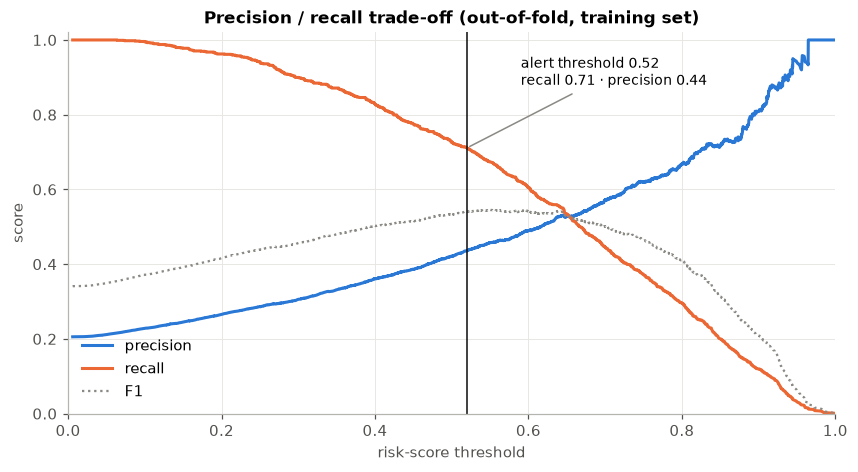

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thr, prec[:-1], color=BLUE, lw=2, label="precision")
ax.plot(thr, rec[:-1], color=ORANGE, lw=2, label="recall")
ax.plot(thr, f1_curve, color=GREY, lw=1.5, ls=":", label="F1")
ax.axvline(ALERT_THRESHOLD, color="#0b0b0b", lw=1)
s_star = score_at(y_train, final_oof, ALERT_THRESHOLD)
ax.annotate(f"alert threshold {ALERT_THRESHOLD:.2f}\nrecall {s_star['recall']:.2f} · "
            f"precision {s_star['precision']:.2f}",
            xy=(ALERT_THRESHOLD, s_star["recall"]), xytext=(ALERT_THRESHOLD + 0.07, 0.88),
            fontsize=9, arrowprops=dict(arrowstyle="-", color=GREY))
ax.set_xlabel("risk-score threshold")
ax.set_ylabel("score")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_title("Precision / recall trade-off (out-of-fold, training set)")
ax.legend(loc="lower left", frameon=False)
plt.show()

**Chart guide: precision and recall across thresholds**

*What the chart shows.* The horizontal axis is the risk-score threshold, and a shipment triggers
an alert when the score reaches or passes the threshold. The blue line is precision (share of
alerts that are truly late), the orange line is recall (share of late shipments caught), and the
dotted grey line is F1 (a single score balancing the two). The black vertical line marks the
chosen threshold of 0.52. All values come from out-of-fold predictions on the training set.

*How to read the curves.*
- At a threshold of 0, every shipment is flagged, so recall is 1.0 and precision equals the late
  share (about 0.21).
- Raising the threshold flags fewer shipments. Precision climbs and recall falls, and the two
  curves cross near a threshold of 0.65, where both are about 0.53.
- At the chosen 0.52, recall is 0.71 and precision is 0.44, as labelled on the chart.
- F1 peaks at about 0.55. The chosen threshold sits just to the left of the peak, trading a very
  small F1 loss for catching more late shipments.
- Precision turns jagged and reaches 1.0 near a threshold of 0.96 because only a handful of
  shipments score that high, so the values there are unreliable.

*Takeaway.* Moving left of the line catches more late shipments but floods dispatch with false
alarms (precision falls below 0.40 at thresholds of 0.45 or lower). Moving right loses recall
quickly (about 0.60 at a threshold of 0.60).

**Key findings: the alert threshold is 0.52**

- **Catches 71% of late shipments**, and 44% of alerts are real (about 1 in 2.3).
- **Going lower gets expensive.** Moving from 0.50 to 0.40 costs 5.6 extra alerts per extra late shipment caught, against 2.4 at 0.50.
- **Going higher loses catches.** Moving from 0.50 to 0.60 loses about 200 late shipments a week.
- **About a third of shipments are flagged (about 2,700 alerts a week)**, so Slack gets one digest per run, with critical shipments (score of 0.80 or higher, about 67% truly late) first.

## 12. Model evaluation on the held-out test set

The test set is used here for the first time. The baseline runs at the default 0.5 threshold.
Showing the final model at both 0.5 and the chosen alert threshold separates the effect of the
model from the effect of the threshold.

In [24]:
dummy_pipe = make_pipeline(DummyClassifier(strategy="most_frequent"), BASE_NUM_COLS).fit(X_train, y_train)
test_proba = {
    "Majority class (Dummy)": dummy_pipe.predict_proba(X_test)[:, 1],
    "Baseline: LogReg (unweighted, raw)": baseline_pipe.predict_proba(X_test)[:, 1],
    "Final: LogReg (weighted, tuned)": final_pipe.predict_proba(X_test)[:, 1],
}
eval_rows = [
    {"model": "Majority class (Dummy)", "threshold": 0.5,
     **score_at(y_test, test_proba["Majority class (Dummy)"])},
    {"model": "Baseline: LogReg (unweighted, raw)", "threshold": 0.5,
     **score_at(y_test, test_proba["Baseline: LogReg (unweighted, raw)"])},
    {"model": "Final: LogReg (weighted, tuned)", "threshold": 0.5,
     **score_at(y_test, test_proba["Final: LogReg (weighted, tuned)"])},
    {"model": "Final: LogReg (weighted, tuned)", "threshold": ALERT_THRESHOLD,
     **score_at(y_test, test_proba["Final: LogReg (weighted, tuned)"], ALERT_THRESHOLD)},
]
test_results = pd.DataFrame(eval_rows).set_index(["model", "threshold"])
test_results.style.format("{:.3f}").format_index("{:.2f}", level=1)

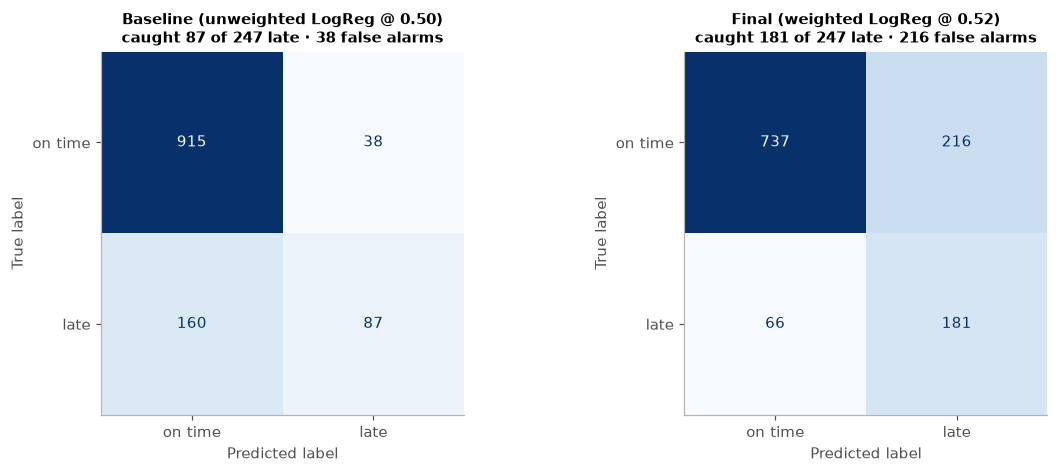

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (title, proba, t) in zip(axes, [
        ("Baseline (unweighted LogReg @ 0.50)", test_proba["Baseline: LogReg (unweighted, raw)"], 0.5),
        (f"Final (weighted LogReg @ {ALERT_THRESHOLD:.2f})",
         test_proba["Final: LogReg (weighted, tuned)"], ALERT_THRESHOLD)]):
    cm = confusion_matrix(y_test, (proba >= t).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["on time", "late"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{title}\ncaught {tp} of {tp + fn} late · {fp} false alarms", fontsize=10)
    ax.grid(False)
fig.tight_layout()
plt.show()

**Chart guide: confusion matrices (test set)**

*What the chart shows.* Each 2 by 2 grid compares true outcomes (rows) with predictions (columns)
for the 1,200 test shipments, with 953 on time and 247 late. The darker the
square, the more shipments fall in the square. The left grid is the baseline at the default 0.5
threshold and the right grid is the final model at 0.52.

*Reading each square.* Top-left: on-time shipments correctly left alone. Top-right: false alarms
(on time but flagged). Bottom-left: missed late shipments (late but not flagged). Bottom-right:
late shipments correctly caught.

*Baseline (unweighted, 0.50).* 915 on-time shipments are correctly left alone and only 38 false
alarms are raised, but 160 of the 247 late shipments are missed and only 87 are caught.
Precision is 87 / 125 = 0.70 and recall is 87 / 247 = 0.35.

*Final model (weighted, 0.52).* 181 late shipments are caught and 66 missed, while false alarms
rise to 216. Precision is 181 / 397 = 0.46 and recall is 181 / 247 = 0.73.

*Takeaway.* Moving from the baseline to the final model trades 178 extra false alarms for 94
more late shipments caught, and the number of missed late shipments drops from 160 to 66.
Because a missed late shipment costs far more than a false alarm, the trade is accepted. The 397
flagged shipments also match the count in the Slack alert.

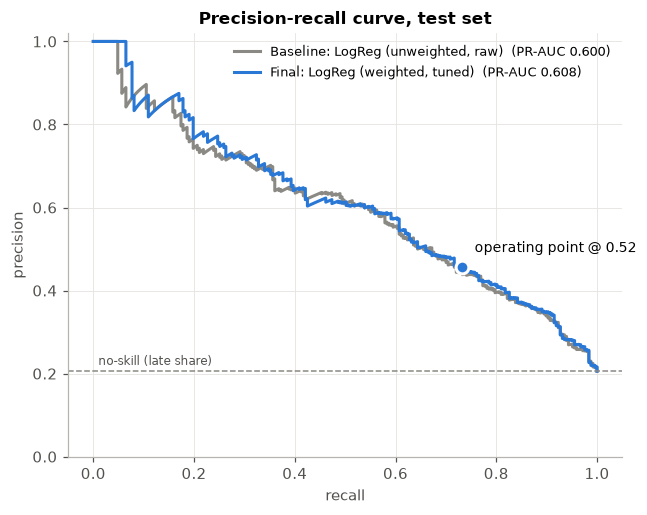

In [26]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for (name, proba), color in zip(list(test_proba.items())[1:], [GREY, BLUE]):
    p, r, _ = precision_recall_curve(y_test, proba)
    ax.plot(r, p, color=color, lw=2, label=f"{name}  (PR-AUC {average_precision_score(y_test, proba):.3f})")
s = score_at(y_test, test_proba["Final: LogReg (weighted, tuned)"], ALERT_THRESHOLD)
ax.scatter([s["recall"]], [s["precision"]], s=70, color=BLUE, edgecolor="white", linewidth=2,
           zorder=3)
ax.annotate(f"operating point @ {ALERT_THRESHOLD:.2f}", (s["recall"], s["precision"]),
            xytext=(8, 10), textcoords="offset points", fontsize=9)
ax.axhline(y_test.mean(), color=GREY, ls="--", lw=1)
ax.text(0.01, y_test.mean() + 0.015, "no-skill (late share)", fontsize=8, color=INK_2)
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_ylim(0, 1.02)
ax.set_title("Precision-recall curve, test set")
ax.legend(loc="upper right", frameon=False, fontsize=8.5)
plt.show()

**Chart guide: precision-recall curve (test set)**

*What the chart shows.* Each point on a curve is one possible threshold. The horizontal axis is
recall (share of late shipments caught) and the vertical axis is precision (share of alerts that
are truly late). A curve closer to the top-right corner is better. The dashed grey line at about
0.21 is a no-skill model that flags shipments at random, and the legend gives the area under
each curve (PR-AUC). The blue dot marks the final model at the chosen 0.52 threshold (recall
0.73, precision 0.46).

*What stands out.*
- Both curves sit well above the no-skill line. At a recall of 0.5, precision is about 0.6,
  roughly three times the late share.
- The baseline (grey, PR-AUC 0.600) and the final model (blue, 0.608) almost overlap. The two
  models rank shipments by risk in nearly the same way.
- Class weights and the threshold choice therefore do not create a better ranking. Only the
  position chosen on the same curve changes. The baseline's default operating point (recall
  0.35, precision 0.70) lies further up and to the left on the same curve, and the final model's
  operating point lies further down and to the right.
- Precision is jagged at the far left because very few shipments score highest, so each shipment
  moves the curve noticeably.

*Takeaway.* Dispatch can slide along the curve to suit the workload, accepting more alerts for
more late shipments caught or fewer alerts for a cleaner channel.

In [27]:
s = score_at(y_test, test_proba["Final: LogReg (weighted, tuned)"], ALERT_THRESHOLD)
b = score_at(y_test, test_proba["Baseline: LogReg (unweighted, raw)"], 0.5)
late_per_week = OVERALL * WEEKLY_SHIPMENTS
print(f"At ~{late_per_week:,.0f} late shipments per week:")
print(f"  baseline flags {b['recall'] * late_per_week:,.0f} late shipments in advance (recall {b['recall']:.2f})")
print(f"  final model flags {s['recall'] * late_per_week:,.0f} late shipments in advance (recall {s['recall']:.2f}),"
      f" i.e. {(s['recall'] - b['recall']) * late_per_week:,.0f} more early warnings per week")

At ~1,645 late shipments per week:
  baseline flags 580 late shipments in advance (recall 0.35)
  final model flags 1,206 late shipments in advance (recall 0.73), i.e. 626 more early warnings per week


**Key findings: results on the test set**

| Test set (1,200 shipments, 247 late) | Precision | Recall | F1 | PR-AUC | Late caught | False alarms |
|---|---|---|---|---|---|---|
| Always "on time" | 0.00 | 0.00 | 0.00 | 0.21 | 0 | 0 |
| Baseline (unweighted, cut-off 0.50) | **0.70** | 0.35 | 0.47 | 0.600 | 87 | 38 |
| Final (weighted, cut-off 0.52) | 0.46 | **0.73** | **0.56** | **0.608** | **181** | 216 |

(Precision is the share of alerts that are really late. Recall is the share of late shipments caught.)

- **About twice as many late shipments caught.** The baseline misses 160 of 247 and the final model misses 66, at the price of 178 more false alarms.
- **The gain comes from the cut-off and class weights, not a smarter model.** Ranking quality is almost the same (PR-AUC 0.600 against 0.608).
- **Business impact.** About 1,200 of roughly 1,650 weekly late shipments are warned of in advance, against about 580 for the baseline.
- **No overfitting.** Test recall (0.73) matches cross-validation recall (0.71).

## 13. Model explainability

Three views: **global** (coefficients and permutation importance), **distributional** (SHAP
beeswarm), and **local** (why one particular shipment was flagged, a question dispatch will ask).

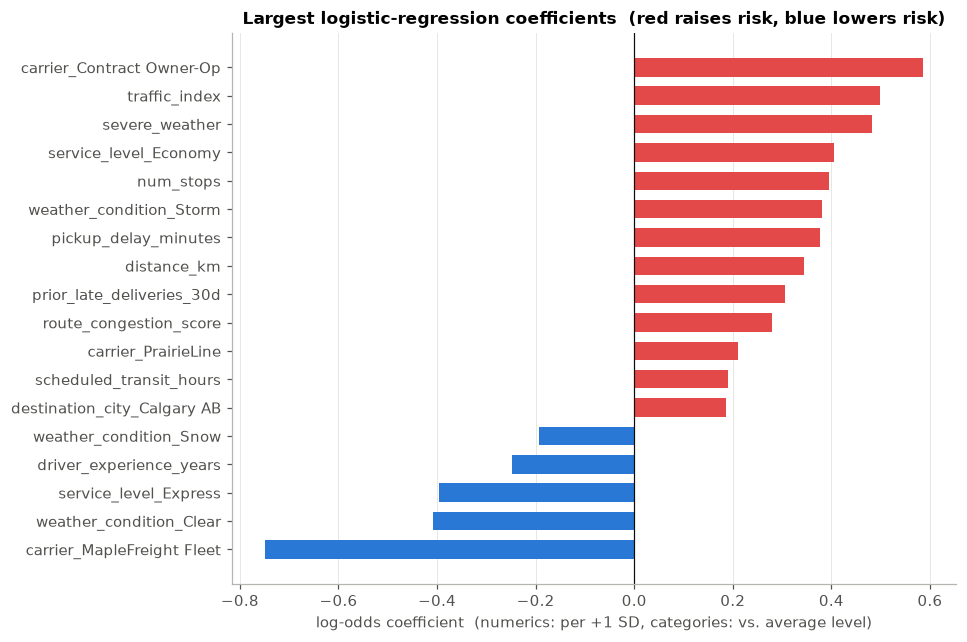

,odds ratio,coef
carrier_MapleFreight Fleet,0.47,-0.75
carrier_Contract Owner-Op,1.80,0.59
traffic_index,1.65,0.50
severe_weather,1.62,0.48
weather_condition_Clear,0.67,-0.41
service_level_Economy,1.50,0.41
service_level_Express,0.67,-0.40
num_stops,1.48,0.40
weather_condition_Storm,1.46,0.38
pickup_delay_minutes,1.46,0.38


In [28]:
prep = final_pipe.named_steps["prep"]
clf = final_pipe.named_steps["model"]
feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

coefs = pd.Series(clf.coef_[0], index=feature_names)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index[:18]).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.barh(top.index, top.values, color=[RED if v > 0 else BLUE for v in top.values], height=0.65)
ax.axvline(0, color="#0b0b0b", lw=0.8)
ax.set_xlabel("log-odds coefficient  (numerics: per +1 SD, categories: vs. average level)")
ax.set_title("Largest logistic-regression coefficients  (red raises risk, blue lowers risk)")
ax.grid(axis="y", visible=False)
plt.show()

odds = np.exp(coefs).rename("odds ratio").to_frame().assign(coef=coefs)
display(odds.reindex(coefs.abs().sort_values(ascending=False).index[:12]).style.format("{:.2f}"))

**Chart guide: logistic-regression coefficients and odds ratios**

*What the chart shows.* Each bar is a coefficient from the final model, measured in log-odds. Red
bars raise the risk of a late delivery, blue bars lower the risk, and a longer bar means a
stronger effect. Numeric columns were standardised, so a numeric coefficient shows the effect of
a one standard deviation increase. A category coefficient shows the effect of that level against
the average level. Only the 18 largest coefficients are drawn. The table below the chart converts
the 12 largest into odds ratios, where a value above 1 raises the odds of lateness and a value
below 1 lowers the odds.

*What stands out.*
- **Carrier:** Contract Owner-Op is the largest risk raiser (+0.59, odds ratio 1.80) and
  MapleFreight Fleet the largest risk reducer (-0.75, odds ratio 0.47). Using the in-house fleet
  roughly halves the odds of a late delivery.
- **Route load:** traffic index (+0.50), number of stops (+0.40), pickup delay (+0.38), distance
  (+0.35), the carrier's prior late deliveries (+0.31) and route congestion (+0.28) all raise
  risk.
- **Weather:** severe weather (+0.48) and Storm (+0.38) raise risk, and Clear lowers risk (-0.41).
- **Service level:** Economy raises risk (+0.41) and Express lowers risk (-0.40).
- **Experience:** more driver experience lowers risk (-0.25).

*Cautions.* Snow shows a small negative coefficient (-0.19), but the value does not mean snow is safe.
The separate severe-weather feature already adds risk for snow, and the Snow coefficient only
adjusts that figure. The net effect of snow is still positive (about +0.29). Distance and
scheduled hours overlap strongly, so the coefficients of the two columns should be read together
and not one by one.

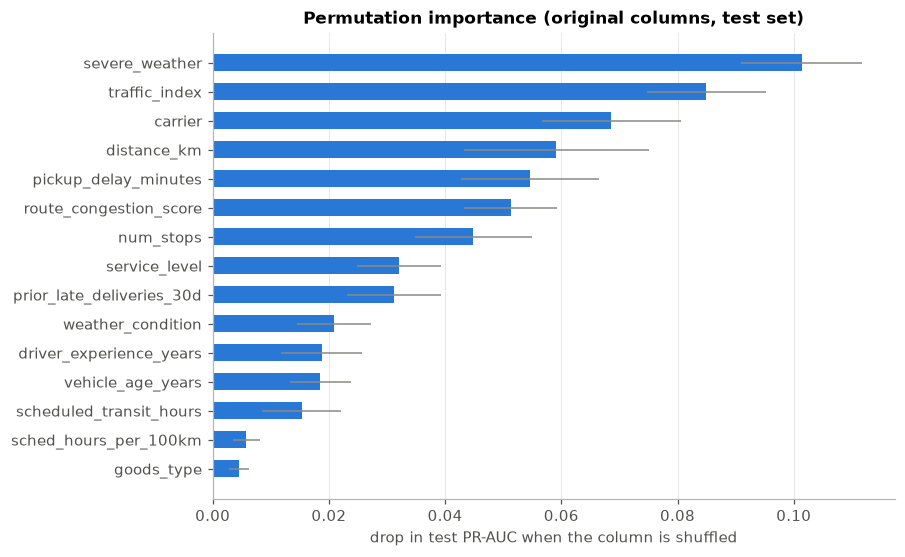

In [29]:
perm = permutation_importance(final_pipe, X_test, y_test, scoring="average_precision",
                              n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = (pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                         index=X_test.columns)
            .sort_values("mean", ascending=False).head(15).iloc[::-1])

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(perm_imp.index, perm_imp["mean"], xerr=perm_imp["std"], color=BLUE, height=0.6,
        error_kw=dict(ecolor=GREY, lw=1))
ax.set_xlabel("drop in test PR-AUC when the column is shuffled")
ax.set_title("Permutation importance (original columns, test set)")
ax.grid(axis="y", visible=False)
plt.show()

**Chart guide: permutation importance (test set)**

*What the chart shows.* Each column in the test set is shuffled at random to break the link
with the outcome, and the drop in PR-AUC is recorded. A longer bar means the model relies more
heavily on the column, because shuffling hurts predictions more. Each bar is an average over 15
shuffles, and the grey whisker shows the standard deviation across the shuffles. Categorical
columns (such as carrier) are shuffled as a whole, so each appears as a single bar.

*What stands out.*
- The top seven columns lose between about 0.045 and 0.10 PR-AUC when shuffled: severe weather
  (0.10), traffic index (0.085), carrier (0.069), distance (0.059), pickup delay (0.055), route
  congestion (0.051) and number of stops (0.045).
- A second tier loses about 0.03 or less: service level, prior late deliveries, weather
  condition, driver experience, vehicle age and scheduled hours.
- Goods type loses about 0.005, essentially nothing, matching the earlier finding that goods type
  barely affects lateness.
- Whiskers of neighbouring bars overlap, so the order inside the top seven is approximate. The
  gap between the top group and the bottom group is clear.
- `severe_weather` and `weather_condition` partly duplicate each other, so shuffling either one
  alone understates the combined importance of weather.

*Takeaway.* Weather, traffic, carrier and route length deserve the closest attention from
dispatch.

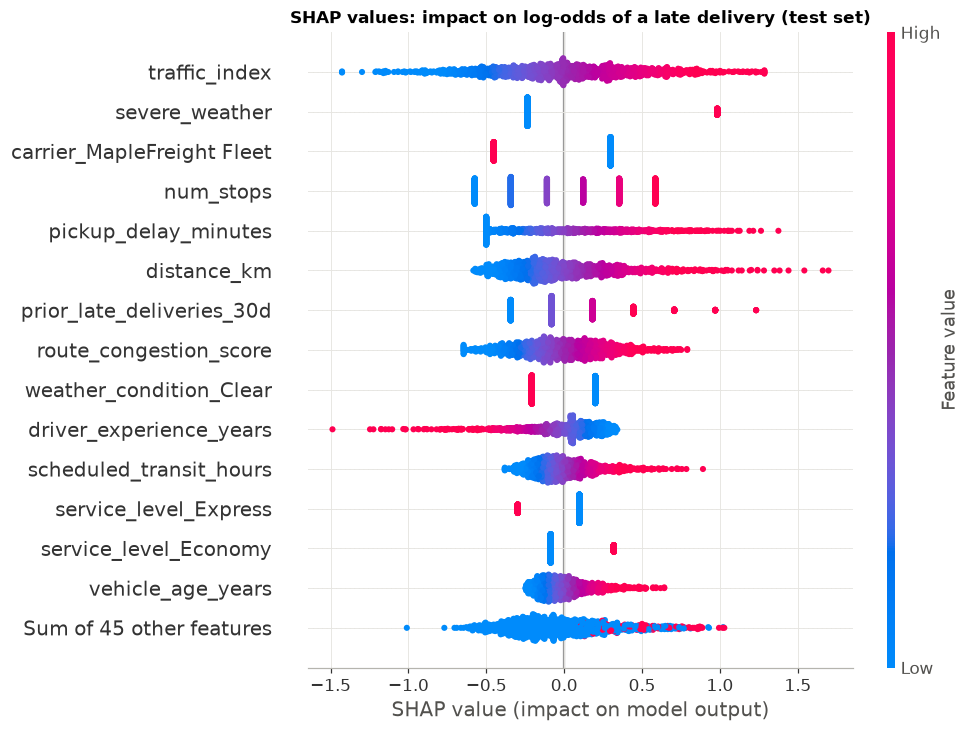

In [30]:
X_train_t = pd.DataFrame(prep.transform(X_train), columns=feature_names)
X_test_t = pd.DataFrame(prep.transform(X_test), columns=feature_names)
explainer = shap.LinearExplainer(clf, shap.maskers.Independent(X_train_t, max_samples=len(X_train_t)))
shap_values = explainer(X_test_t)
# For display, show numerics in original units (imputed, unscaled) instead of z-scores.
num_unscaled = prep.named_transformers_["num"].named_steps["impute"].transform(X_test[FULL_NUM_COLS])
shap_values.display_data = np.column_stack([num_unscaled, X_test_t.iloc[:, len(FULL_NUM_COLS):]]) + 0.0  # +0.0 turns -0 into 0
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP values: impact on log-odds of a late delivery (test set)")
plt.show()

**Chart guide: SHAP beeswarm (test set)**

*What the chart shows.* Every dot is one test shipment. The horizontal position shows how far a
column pushed the risk score for that shipment, to the right for higher risk and to the left for
lower risk (measured in log-odds). The colour shows the column's value for the shipment, red for
high and blue for low. Rows are sorted by the average size of the push, so the most influential
columns sit at the top. The last row combines the 45 smallest columns.

*What stands out.*
- **Traffic index:** the widest spread, from about -1.4 for the quietest routes to about +1.3 for
  the busiest. Colour changes smoothly from blue to red along the axis, showing a steady link
  between traffic and risk.
- **Severe weather:** only two clusters, near -0.25 for normal weather and near +1.0 for snow or
  storm. The +1.0 push is large, though only a minority of shipments are affected.
- **Carrier (MapleFreight Fleet):** red dots (in-house fleet) sit near -0.45, and blue dots
  (other carriers) sit near +0.3.
- **Number of stops and prior late deliveries:** dots form separate columns because the values
  are whole numbers. The push for stops grows from about -0.6 at no stops to about +0.6 at five
  stops, and the push for prior late deliveries reaches about +1.2 at the highest counts.
- **Pickup delay and distance:** long tails to the right show that a few very late pickups (up to
  +1.4) and very long routes (up to +1.7) add a lot of risk.
- **Driver experience:** red dots (very experienced drivers) reach as far left as -1.5, so
  experience is protective. Blue dots (novices) push risk slightly upward.
- **Service level:** Express (red) lowers risk by about 0.3 and Economy (red) raises risk by
  about 0.3.

*Takeaway.* The smooth colour gradients show effects that grow steadily with the value of each
column. The chart agrees with the coefficients and the permutation importance, and adds the
spread of the effects across individual shipments. The order differs slightly from the
permutation chart because SHAP ranks by average push, and rare but large pushes (such as severe
weather) count for less on average.

SHP-100936: Toronto ON → Calgary AB, PrairieLine, Storm, traffic 78, 5 stops, pickup delay 0 min | risk score 0.98


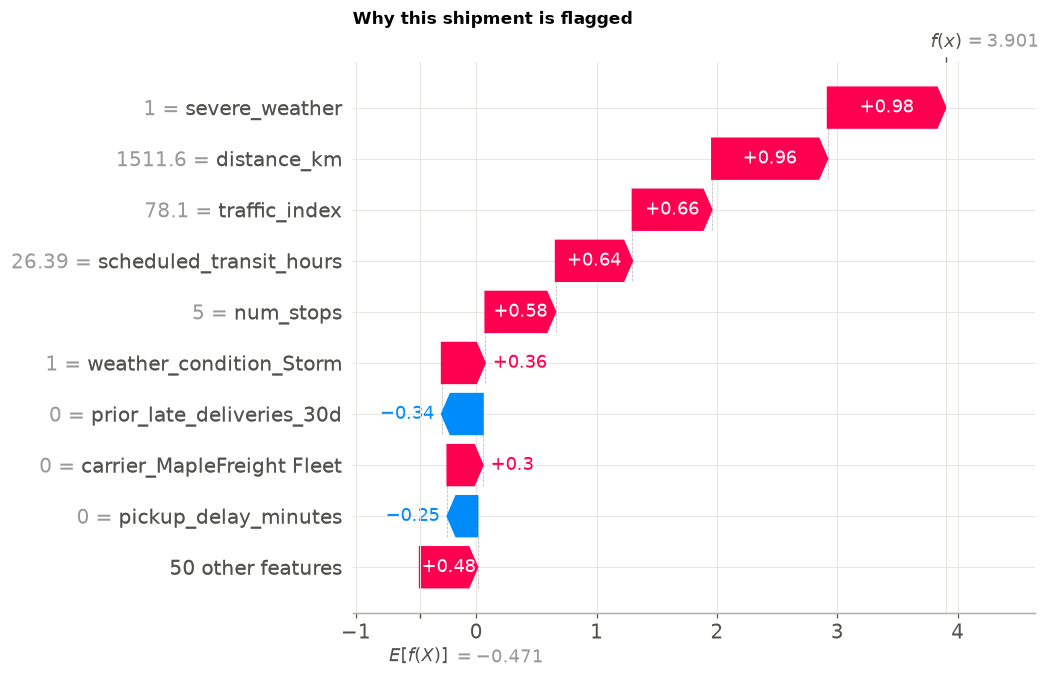

In [31]:
# Local explanation for the shipment dispatch would see at the top of the Slack alert.
top_idx = int(np.argmax(test_proba["Final: LogReg (weighted, tuned)"]))
top_row = model_df.loc[X_test.index[top_idx]]
print(f"{top_row['shipment_id']}: {top_row['origin_city']} → {top_row['destination_city']}, "
      f"{top_row['carrier']}, {top_row['weather_condition']}, traffic {top_row['traffic_index']:.0f}, "
      f"{top_row['num_stops']} stops, pickup delay {top_row['pickup_delay_minutes'] + 0:.0f} min | "
      f"risk score {test_proba['Final: LogReg (weighted, tuned)'][top_idx]:.2f}")
shap.plots.waterfall(shap_values[top_idx], max_display=10, show=False)
plt.title("Why this shipment is flagged", loc="left")
plt.show()

**Chart guide: SHAP waterfall for the highest-risk shipment (SHP-100936)**

*What the chart shows.* The chart explains one prediction step by step. The path starts at the
bottom with the average model output over the training data (E[f(X)] = -0.471 in log-odds). Each
bar then adds (red) or subtracts (blue) the push from one column for the shipment, and the top
value f(x) = 3.901 is the final score in log-odds, equal to a risk score of 0.98. The grey
number beside each label is the shipment's actual value for the column. Class weighting raises
the average above the true late share of 20.6%.

*What drives the score.*
- **Severe weather = 1 (+0.98):** a storm forecast is the largest single push.
- **Distance = 1,511.6 km (+0.96):** a long route from Toronto to Calgary.
- **Traffic index = 78.1 (+0.66):** heavy congestion at dispatch.
- **Scheduled hours = 26.39 (+0.64)** and **five stops (+0.58):** a long, multi-stop trip.
- **Storm (+0.36):** adds to the severe-weather push.
- **Carrier is not MapleFreight Fleet (+0.30):** the shipment travels with PrairieLine and not
  the in-house fleet.
- **No late deliveries by the carrier in 30 days (-0.34)** and **an on-time pickup (-0.25):** the
  only two factors in the chart that lower the risk.
- The remaining 50 columns together add +0.48.

*Takeaway.* The high score comes from weather, route length and traffic, not from carrier history
or pickup timing. Dispatch cannot change the weather, but a customer call or a weather re-route
addresses the actual cause better than a carrier swap.

**Key findings: explaining the model**

- **Most important columns.** Shuffling each column in turn and measuring the loss in accuracy
  ranks the drivers as: severe weather, traffic, carrier, distance, pickup delay, route
  congestion, number of stops, service level, and the carrier's late deliveries in the last 30
  days. Driver experience and vehicle age matter less.
- **Size of the effects.** Using the in-house fleet roughly halves the odds of a late delivery
  (odds ratio 0.47). A contract owner-operator multiplies the odds by 1.8. A large jump in traffic
  (one standard deviation) multiplies the odds by 1.65, and Economy service by 1.5, while Express
  lowers the odds (0.67).
- **A confusing number.** `weather_condition_Snow` has a negative coefficient, but snow is not
  safe. The `severe_weather` feature already adds risk for snow and storms, and the Snow
  coefficient only corrects the adjustment. Overall, snow still raises risk.
- Customer tier, goods type, city, weight and fuel cost have almost no effect, matching the
  earlier analysis.
- **The example alert.** The highest-risk shipment is a storm on a long (Toronto to Calgary,
  1,512 km), five-stop, high-traffic trip. An on-time pickup and no late deliveries by the carrier
  in the past 30 days lower the risk a little. Dispatch can see that the risk comes from route
  and weather, so a weather re-route or a call to the customer helps more than changing the
  carrier.

## 14. Slack alert integration


In [32]:
load_dotenv(find_dotenv(usecwd=True))
SLACK_WEBHOOK_URL = os.getenv("SLACK_WEBHOOK_URL", "").strip()
# Only report whether a webhook is configured. The URL itself is a secret and is never printed.
print("Slack webhook configured:", bool(SLACK_WEBHOOK_URL))
if SLACK_WEBHOOK_URL and not SLACK_WEBHOOK_URL.startswith("https://hooks.slack.com/"):
    print("Warning: SLACK_WEBHOOK_URL does not look like a Slack incoming-webhook URL.")

Slack webhook configured: True


In [33]:
CRITICAL_SCORE = 0.80

in_transit = model_df.loc[X_test.index, ["shipment_id", "origin_city", "destination_city",
                                         "carrier", "weather_condition"]].copy()
in_transit["risk_score"] = final_pipe.predict_proba(X_test)[:, 1]
at_risk = (in_transit[in_transit["risk_score"] >= ALERT_THRESHOLD]
           .sort_values("risk_score", ascending=False))
print(f"{len(at_risk):,} of {len(in_transit):,} in-transit shipments at or above {ALERT_THRESHOLD:.2f}, "
      f"{(at_risk['risk_score'] >= CRITICAL_SCORE).sum()} critical (≥ {CRITICAL_SCORE:.2f})")
at_risk.head(10)

397 of 1,200 in-transit shipments at or above 0.52, 109 critical (≥ 0.80)


,shipment_id,origin_city,destination_city,carrier,weather_condition,risk_score
5268,SHP-100936,Toronto ON,Calgary AB,PrairieLine,Storm,0.980
1555,SHP-103230,Montreal QC,Regina SK,Contract Owner-Op,Snow,0.971
3041,SHP-105511,Toronto ON,Ottawa ON,NorthStar Carriers,Snow,0.969
554,SHP-103300,Mississauga ON,Winnipeg MB,NorthStar Carriers,Snow,0.969
3632,SHP-100273,Montreal QC,Hamilton ON,NorthStar Carriers,Snow,0.967
2110,SHP-102910,Montreal QC,Edmonton AB,QuebecExpress,Storm,0.959
955,SHP-101710,Montreal QC,Sudbury ON,MapleFreight Fleet,Storm,0.957
1481,SHP-104995,Montreal QC,Winnipeg MB,NorthStar Carriers,Storm,0.952
939,SHP-101673,Toronto ON,Sudbury ON,Contract Owner-Op,Snow,0.951
504,SHP-103708,Toronto ON,Winnipeg MB,PrairieLine,Storm,0.941


In [34]:
def build_alert_message(at_risk: pd.DataFrame, n_scored: int, threshold: float,
                        top_n: int = 5, critical: float = CRITICAL_SCORE) -> str:
    """Short, phone-friendly digest: the count first, then the top shipments, one per line."""
    if at_risk.empty:
        return (f":white_check_mark: *MapleFreight delay check*: none of {n_scored:,} in-transit "
                f"shipments is above risk {threshold:.2f}.")
    n_critical = int((at_risk["risk_score"] >= critical).sum())
    lines = [
        ":rotating_light: *MapleFreight late-delivery alert*",
        f"*{len(at_risk):,} of {n_scored:,}* in-transit shipments at risk of missing their window",
        f"({n_critical} critical ≥ {critical:.2f} · alert threshold {threshold:.2f})",
        "",
        f"*Top {min(top_n, len(at_risk))} by risk score:*",
    ]
    for i, r in enumerate(at_risk.head(top_n).itertuples(index=False), start=1):
        lines.append(f"{i}. `{r.shipment_id}` → {r.destination_city} · {r.carrier} · "
                     f"*{r.risk_score:.2f}*")
    lines += ["", "_Re-route or warn the customer before the delivery window closes._"]
    return "\n".join(lines)


def send_slack_alert(text: str, webhook_url: str, timeout: float = 10) -> bool:
    """POST the message to the Slack incoming webhook. Never echoes the URL."""
    if not webhook_url:
        print("SLACK_WEBHOOK_URL is not set: message NOT sent (copy .env.example to .env).")
        return False
    try:
        resp = requests.post(webhook_url, json={"text": text}, timeout=timeout)
    except requests.RequestException as exc:
        # str(exc) would include the full webhook URL, so print only the exception type.
        print(f"Slack post failed: {type(exc).__name__}")
        return False
    print(f"Slack responded HTTP {resp.status_code}: {resp.text[:40]}")
    return resp.ok


alert_text = build_alert_message(at_risk, n_scored=len(in_transit), threshold=ALERT_THRESHOLD)
print(alert_text)

:rotating_light: *MapleFreight late-delivery alert*
*397 of 1,200* in-transit shipments at risk of missing their window
(109 critical ≥ 0.80 · alert threshold 0.52)

*Top 5 by risk score:*
1. `SHP-100936` → Calgary AB · PrairieLine · *0.98*
2. `SHP-103230` → Regina SK · Contract Owner-Op · *0.97*
3. `SHP-105511` → Ottawa ON · NorthStar Carriers · *0.97*
4. `SHP-103300` → Winnipeg MB · NorthStar Carriers · *0.97*
5. `SHP-100273` → Hamilton ON · NorthStar Carriers · *0.97*

_Re-route or warn the customer before the delivery window closes._


In [35]:
sent = send_slack_alert(alert_text, SLACK_WEBHOOK_URL)
print("Alert delivered to #dispatch-alerts" if sent else "Alert not delivered")

Slack responded HTTP 200: ok
Alert delivered to #dispatch-alerts


**Key findings: Slack alert.** The alert is one message per run. The message starts with the
number of shipments at risk, the first figure a dispatcher reads on a phone. The five riskiest
shipments follow, each with ID, destination, carrier and risk score. A screenshot of the message
is in `screenshots/slack_alert.png`. In real use, I think the sending cell would run on a schedule (for example
every 30 minutes) against the current in-transit shipments.

## 15. Recommendations

**Operational (act on the alert)**

1. **Put the model in the dispatch loop.** Score in-transit shipments every 30 minutes and post
   the digest to `#dispatch-alerts` at threshold 0.52. On the test set, 73% of late shipments
   (about 1,200 a week) were flagged while the delivery window was still open. Handle **critical
   (≥ 0.80)** shipments first by re-routing, swapping in a fleet truck, or calling the customer
   proactively to reset expectations. Early contact can avoid the service credit under many
   contracts.
2. **Weather playbook.** Storm and snow forecasts are the largest single risk factor (46% and 34%
   late against 14% in clear weather). On such days, pad promised windows automatically, move
   pickups earlier, and avoid assigning owner-operators to severe-weather lanes.

**Structural (lower the base rate)**

3. **Carrier management.** Contract owner-operators are late 36% of the time against 13% for the
   in-house fleet, and the gap persists in every weather type. Prioritise the fleet for Gold
   accounts and for storm and snow days, and add on-time SLAs with penalties to owner-operator
   contracts. Use `prior_late_deliveries_30d` as a live carrier scorecard.
4. **Make the priority tier meaningful.** Gold, Silver and Bronze accounts are all late about 21%
   of the time, so priority is not reaching dispatch decisions. Route Gold and Express loads to
   the in-house fleet and experienced drivers first. Economy loads (27% late) need more
   realistic promised windows.
5. **Fix pickups.** The late rate climbs steadily with pickup delay. Treat any pickup more than
   30 minutes late as an automatic trigger for a new score and an alert, and review dock
   scheduling at the worst origins.
6. **Quote realistic transit times.** Long, multi-stop, high-traffic routes are late far more
   often. Build traffic, stop count and route congestion into `scheduled_transit_hours` instead
   of promising the same speed on every lane.
7. **Driver pairing.** Drivers in the first couple of years of experience are late noticeably more
   often. Pair novices with low-risk lanes (clear weather, few stops) and keep experienced
   drivers for high-risk loads.

**Data and model**

8. **Fix the export at the source.** Enforce kg units, a controlled vocabulary for
   `service_level`, and unique `shipment_id`s, and capture the weather forecast for every
   shipment.
9. **Add in-transit signals.** All current features are known at dispatch. GPS progress versus
   plan, live traffic and driver hours-of-service would allow the score to update during the
   trip, the most likely source of further accuracy.
10. **Close the loop.** Log the alerts dispatch acted on and the outcomes, retrain monthly, and
    track recall and precision on a dashboard so drift is caught early.

## 16. Limitations and next steps

- **Limit on ranking quality.** Every model family plateaus around 0.81 ROC-AUC and 0.56 PR-AUC.
  The dispatch-time features explain only part of the variation, and additional signals (see
  recommendation 9) will help more than a more complex model.
- **Risk scores are not calibrated probabilities**, because class weighting inflates the scores.
  If the business wants a "probability of lateness", add `CalibratedClassifierCV` and keep the
  threshold logic on the calibrated scale.
- **Threshold economics are qualitative.** With the real cost per service credit and per
  dispatcher intervention, the threshold should be re-derived by minimising expected cost
  directly.
- **Single snapshot.** The data has no dates beyond month, so a time-based split was not possible.
  In production, validate on the most recent weeks to catch drift.